# T3.1 Leakage: no gradient

**Purpose** (Table 4.2, D-5 validation plan): leakage results from the correlation of azimuthal NRCS gradients with the geometric Doppler and the beam pattern.
Here we test whether the absence of azimuthal NRCS gradients indeed precludes any leakage from occurring, by generating a uniform NRCS field along azimuth
with an NRCS GMF (CMOD5.N) and using it in place of the actual SCA-NRCS.

**Implementation**
1. Estimate SWB geometric Doppler and beam pattern
2. Generate a uniform NRCS field using an NRCS GMF
3. Estimate leakage

**Requirements**: reference simulation SWB-SCA (California geometry), NRCS GMF (CMOD5.N), EUMETSAT beam pattern

This notebook performs the test and reports the results for interpretation. No tolerances or pass/fail criteria are applied.

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
from matplotlib import pyplot as plt

from stereoid.oceans.forward_models.cmod5n import cmod5n_forward
from sca_module.readers import create_dataset
from sca_module.dopsca_setup import DopSCAConfig
from sca_module.simulate_L1 import compute_cube_observation_geometry, compute_observations, create_observation_cube

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

## 0 - Parameters

In [2]:
sca = DopSCAConfig()
sca.Lambda = sca.get_wavelength()
# The magic_divider is an unnecessary, but convenient, method to resample the input data to some common sampling.
sca.grid_spacing_target = sca.get_grid_spacing_target(magic_divider=2)

# the uniform NRCS level is irrelevant for leakage (it cancels in the beam weights), only its shape along azimuth matters
wind_direction_wrt_sensor = 45 # [deg], fixed wind direction w.r.t. the look direction for CMOD5.N

## 1 - Load data
Only the geometry (ground range, incidence) of the SWB simulation is used.

In [3]:
files_cali = [
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_California.nc',
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc'
]

simulation = xr.open_mfdataset(files_cali, compat='no_conflicts', engine='netcdf4').sel(sat = 'S1').compute()
sca.magic_offset = sca.get_magic_offset(incidence_min=simulation.inc.min().data)

# clipping unreasonable incidence angles
simulation = simulation.sel(grg = slice(sca.grg_min - sca.magic_offset, sca.grg_max - sca.magic_offset))
simulation = simulation.assign_coords(grg = simulation.grg + sca.magic_offset)

# Here we interpolate to finer grid spacing,
new_az = np.arange(simulation.az.min(), simulation.az.max(), sca.grid_spacing_target)
new_grg = np.arange(simulation.grg.min(), simulation.grg.max(), sca.grid_spacing_target)
simulation = simulation.interp(az=new_az, grg=new_grg)

# EUMETSAT beam pattern, as in the uncertainty notebooks
beam_SCA = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/data/beam_pattern_updated.nc')['beam_sca']

## 2 - Uniform NRCS field from CMOD5.N
CMOD5.N for the configured wind speed and a fixed direction at each ground range, identical at every azimuth.

In [4]:
inc_deg = np.degrees(simulation[sca.var_inc].data)
sigma0_range = cmod5n_forward(
    v=np.full_like(inc_deg, sca.U),
    phi=np.full_like(inc_deg, wind_direction_wrt_sensor),
    theta=inc_deg,
)
nrcs_uniform = np.broadcast_to(sigma0_range[None, :], (simulation.sizes['az'], simulation.sizes['grg'])).copy()

## 3 - Estimate leakage
No geophysical Doppler is included, so the beam integrated velocity is the leakage only.

In [5]:
inc_2d = np.degrees(simulation[sca.var_inc].expand_dims(dim={sca.dim_az: simulation.az.data}))

data = create_dataset(
    nrcs=nrcs_uniform,
    dop=np.zeros_like(nrcs_uniform),
    inc=inc_2d.data,
    grg=simulation.grg.data,
    az=simulation.az.data,
    grid_spacing=sca.grid_spacing_target,
)

# dropna (default): only pulses whose whole azimuth footprint lies inside the scene are kept
data_cube = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF).compute()
data_cube = compute_cube_observation_geometry(data_cube, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
data_cube['beam']= beam_SCA.interp(az_beam=data_cube.az_beam, grg=data_cube.grg, method='linear')

data_cube = compute_observations(data_cube, sca.var_nrcs, sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")
V_leakage = data_cube["V_leakage_pulse_rg"].transpose(sca.dim_az_slow_time, sca.dim_range)

# Results
## Summary
Leakage in m/s. The azimuthal standard deviation measures any leakage variation along azimuth.

In [6]:
summary = pd.Series({
    "mean": V_leakage.mean().item(),
    "max azimuthal std": V_leakage.std(dim=sca.dim_az_slow_time).max().item(),
}).to_frame("California [m/s]")
summary

,California [m/s]
mean,-3.501185e-01
max azimuthal std,9.992007e-16


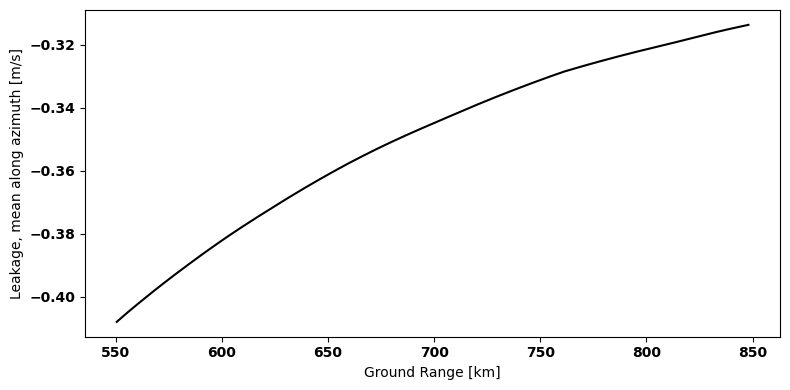

In [7]:
fig, ax = plt.subplots(figsize = (8, 4))
ax.plot(V_leakage[sca.dim_range] / 1e3, V_leakage.mean(dim=sca.dim_az_slow_time), color = 'k')
ax.set_xlabel("Ground Range [km]")
ax.set_ylabel("Leakage, mean along azimuth [m/s]")
plt.tight_layout()

## Beam pattern
The source of the remaining leakage: the two-way EUMETSAT beam (left, normalised by its peak) is slightly asymmetric about boresight (right,
$\big(B(x) - B(-x)\big) / \max B$). This shifts the beam centroid (black line, scaled by 100 for visibility) off boresight, so the geometric Doppler on either side of boresight is weighted
unequally, which leaves a constant leakage even without NRCS gradients.

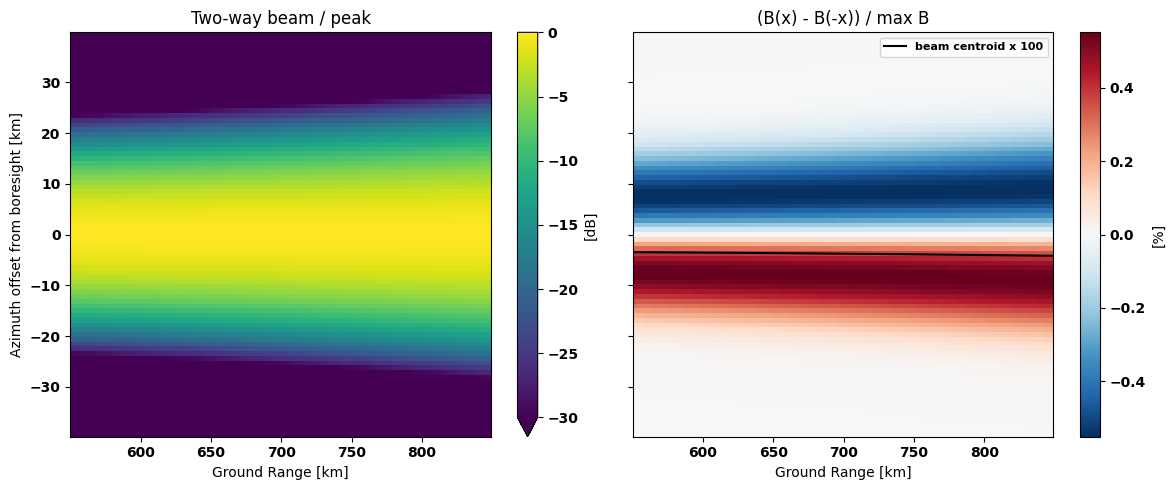

In [8]:
beam_norm = beam_SCA / beam_SCA.max(dim=sca.dim_az_beam)
asymmetry = beam_norm - beam_norm.isel({sca.dim_az_beam: slice(None, None, -1)}).data # B(x) - B(-x), normalised by the peak
centroid = (beam_SCA * beam_SCA[sca.dim_az_beam]).sum(sca.dim_az_beam) / beam_SCA.sum(sca.dim_az_beam) # beam centroid along azimuth [m]
to_km = lambda da: da.assign_coords({name: da[name] / 1e3 for name in da.dims})

fig, axes = plt.subplots(ncols=2, nrows=1, sharex=True, sharey=True, figsize = (12, 5))
(10 * np.log10(to_km(beam_norm))).plot(ax = axes[0], x = sca.dim_range, vmin = -30, vmax = 0, cmap = 'viridis', cbar_kwargs={"label": "[dB]"})
(100 * to_km(asymmetry)).plot(ax = axes[1], x = sca.dim_range, cmap = 'RdBu_r', cbar_kwargs={"label": "[%]"})
axes[1].plot(centroid[sca.dim_range] / 1e3, 100 * centroid / 1e3, color = 'k', lw = 1.5, label = "beam centroid x 100")
axes[1].legend(fontsize = 8)
_ = axes[0].set_title("Two-way beam / peak")
_ = axes[1].set_title("(B(x) - B(-x)) / max B")
_ = [ax.set_xlabel("Ground Range [km]") for ax in axes]
_ = axes[0].set_ylabel("Azimuth offset from boresight [km]")
_ = axes[1].set_ylabel("")
plt.tight_layout()